# SCA reconstruction: old port vs original-faithful port

Runs both versions of the SCA gap-filling UDF locally on the same input cube and compares the result.

- **old**: `scripts/old_udfs/snow_cover_area_reconstruction_udf.py`, the port before this change.
- **new**: `src/.../snow_cover_area/udfs/snow_cover_area_reconstruction_udf.py`, which follows dailyHR_SCA. It has two blocks, uses the original similarity thresholds, puts the LR SCF on 500 m blocks, assigns CP only where it is 0/1, and applies rule0100.

The default input is synthetic, so the true snow under the clouds is known. Set `REAL_INPUT` to a NetCDF of the `sca_inputs` cube (bands `snow`, `scf`, `cp_*`, `occ_*`) to run on real data. Both UDFs get the same cube, with CP as a 0-1 fraction as the pipeline produces it.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import ListedColormap, BoundaryNorm
from openeo.udf import UdfData, XarrayDataCube
from openeo.udf.run_code import run_udf_code

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
OLD_UDF = ROOT / 'scripts/old_udfs/snow_cover_area_reconstruction_udf.py'
NEW_UDF = ROOT / 'src/openeo_mountains_snow/snow_cover_area/udfs/snow_cover_area_reconstruction_udf.py'
REAL_INPUT = None  # e.g. ROOT / 'tmp/sca_inputs.nc'
N_DAYS = 30


def run_udf(path, cube, context):
    data = UdfData(datacube_list=[XarrayDataCube(cube)], user_context=context)
    return run_udf_code(code=Path(path).read_text(), data=data).get_datacube_list()[0].get_array()

## Synthetic input

- **Snow:** a 2 km x 2 km grid at 20 m, which covers 4x4 LR pixels of 500 m. Snow is present where a terrain-like field `z` lies above a snow line. The snow line oscillates with a 30-day period, so similar historical scenes exist.
- **Clouds:** smooth random blobs. A few pixels are permanent no data (NaN).
- **MODIS SCF:** the true fraction per 500 m block plus noise. A block is 205 when more than half of it is cloudy.
- **CP and occurrences:** built from the observed history in the same way as `compute_conditional_probability`, with buffered ranges and 0-1 CP.

In [7]:
rng = np.random.default_rng(42)
NT, NY, NX, RES, LR = 90, 100, 100, 20.0, 500.0
x = 650_000 + RES / 2 + RES * np.arange(NX)
y = 5_150_000 - RES / 2 - RES * np.arange(NY)
yy, xx = np.indices((NY, NX))
z = 0.7 * yy / NY + 0.15 * np.sin(xx / 9) + 0.1 * np.cos(yy / 7 + xx / 13) + 0.03 * rng.standard_normal((NY, NX))

line = 0.45 + 0.3 * np.sin(2 * np.pi * np.arange(NT) / 30) + 0.01 * rng.standard_normal(NT)
truth = np.where(z[None] > line[:, None, None], 100.0, 0.0)


def smooth_field():
    f = np.zeros((NY, NX))
    for _ in range(6):
        k = rng.uniform(0.03, 0.12, 2)
        f += np.sin(k[0] * yy + rng.uniform(0, 6.3)) * np.cos(k[1] * xx + rng.uniform(0, 6.3))
    return f


cloud = np.zeros((NT, NY, NX), bool)
for t in range(NT):
    frac = 0.0 if rng.random() < 0.4 else rng.uniform(0.05, 0.7)
    if frac:
        f = smooth_field()
        cloud[t] = f > np.quantile(f, 1 - frac)
nodata = rng.random((NY, NX)) < 0.01

observed = np.where(cloud, 205.0, truth)
observed[:, nodata] = np.nan

iy = (np.floor(y / LR) - np.floor(y / LR).min()).astype(int)
ix = (np.floor(x / LR) - np.floor(x / LR).min()).astype(int)
labels = iy[:, None] * (ix.max() + 1) + ix[None, :]
n_lr = labels.max() + 1


def block_mean(a):
    return (np.bincount(labels.ravel(), weights=a.ravel(), minlength=n_lr) / np.bincount(labels.ravel(), minlength=n_lr))[labels]


modis = np.stack([np.clip(block_mean(truth[t]) + rng.normal(0, 5), 0, 100) for t in range(NT)])
modis_cloudy = np.stack([block_mean(cloud[t].astype(float)) > 0.5 for t in range(NT)])
modis = np.where(modis_cloudy, 205.0, modis)

# conditional probability as in conditional_probability.py (buffered ranges, HR aggregate, valid > 90%)
valid = np.isfinite(observed) & (observed <= 100)
hr_scf = np.stack([np.where(block_mean(valid[t].astype(float)) > 0.9,
                            100 * block_mean(np.where(valid[t], observed[t], 0) / 100) / block_mean(valid[t].astype(float)), np.nan)
                   for t in range(NT)])
ranges = [(max(0, lo - 10), min(100, lo + 20)) for lo in range(0, 100, 10)]
cp, occ = [], []
for lo, hi in ranges:
    in_range = ((hr_scf >= lo) if lo == 0 else (hr_scf > lo)) & (hr_scf <= hi)
    occ.append(in_range.sum(0).astype(float))
    snow_sum = (in_range & (observed == 100)).sum(0)
    with np.errstate(invalid='ignore', divide='ignore'):
        cp.append(snow_sum / occ[-1])


def at_t0(a):
    out = np.full((NT, NY, NX), np.nan)
    out[0] = a
    return out


bands = {'snow': observed, 'scf': modis}
bands |= {f'cp_{lo}_{hi}': at_t0(c) for (lo, hi), c in zip(ranges, cp)}
bands |= {f'occ_{lo}_{hi}': at_t0(o) for (lo, hi), o in zip(ranges, occ)}
cube = xr.DataArray(np.stack(list(bands.values()), axis=1).astype(np.float32), dims=('t', 'bands', 'y', 'x'),
                    coords={'t': pd.date_range('2023-01-01', periods=NT), 'bands': list(bands), 'y': y, 'x': x})

if REAL_INPUT:
    ds = xr.open_dataset(REAL_INPUT)
    names = [v for v in ds.data_vars if v != 'crs']
    cube = ds[names].to_array('bands').transpose('t', 'bands', 'y', 'x').astype(np.float32)
    truth = None
print(cube.sizes)

C:\Users\VROMPAYH\AppData\Local\Temp\ipykernel_5784\834716318.py:48: RuntimeWarning: invalid value encountered in divide
  100 * block_mean(np.where(valid[t], observed[t], 0) / 100) / block_mean(valid[t].astype(float)), np.nan)


Frozen({'t': 90, 'bands': 22, 'y': 100, 'x': 100})


In [8]:
runs = {
    'old': run_udf(OLD_UDF, cube, {'n_days_to_reconstruct': N_DAYS}),
    'new': run_udf(NEW_UDF, cube, {'n_days_to_reconstruct': N_DAYS}),
    'new, rule0100 off': run_udf(NEW_UDF, cube, {'n_days_to_reconstruct': N_DAYS, 'rule0100': False}),
}
days = runs['new'].t.values
inp = cube.sel(t=days).isel(bands=0).fillna(255).values
ref = None if truth is None else truth[-len(days):]

## Per-day statistics

| Column | Meaning |
|---|---|
| `filled` | Share of the cloudy input pixels that got 0 or 100 |
| `acc_filled` | Agreement with the truth on those filled pixels (synthetic input only) |
| `clear_changed` | Clear input pixels whose value changed (rule0100 overrides) |

,cloud_frac,filled,acc_filled,clear_changed
run,,,,
new,0.1921,0.413117,0.998444,0
"new, rule0100 off",0.1921,0.398020,0.998378,0
old,0.1921,0.268199,0.668352,0


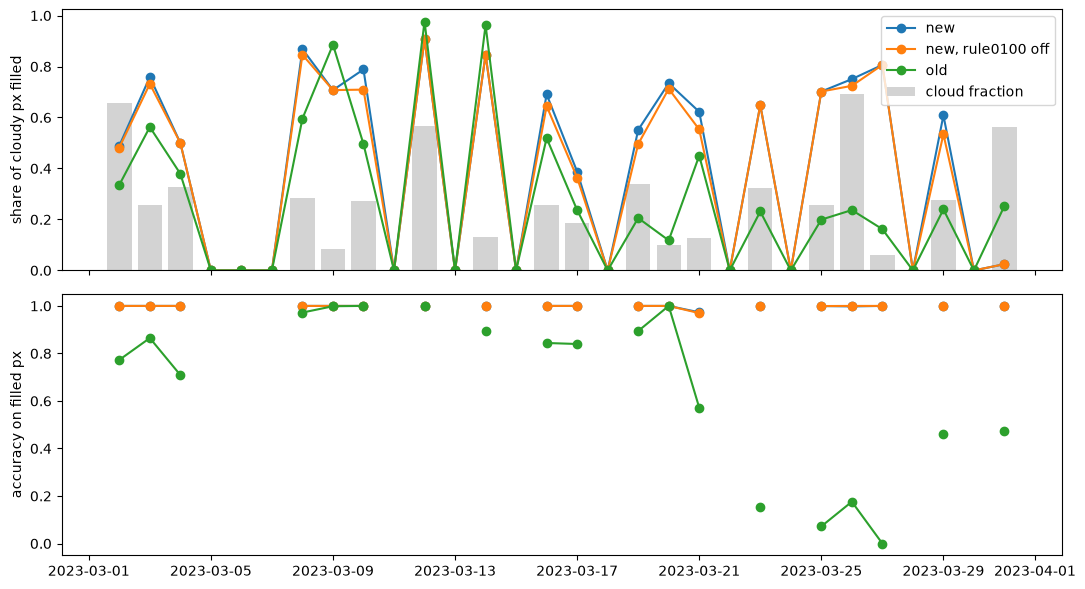

In [9]:
rows = []
for name, res in runs.items():
    out = res.isel(bands=0).values.astype(float)
    for k, day in enumerate(days):
        cl = inp[k] == 205
        clear = inp[k] <= 100
        filled = cl & (out[k] <= 100)
        row = {'run': name, 'day': pd.Timestamp(day), 'cloud_frac': cl.mean(),
               'filled': filled.sum() / max(cl.sum(), 1), 'clear_changed': (clear & (out[k] != inp[k])).sum()}
        if ref is not None:
            row['acc_filled'] = (out[k][filled] == ref[k][filled]).mean() if filled.any() else np.nan
            row['acc_clear_changed'] = (out[k][clear & (out[k] != inp[k])] == ref[k][clear & (out[k] != inp[k])]).mean() if (clear & (out[k] != inp[k])).any() else np.nan
        rows.append(row)
stats = pd.DataFrame(rows)
display(stats.groupby('run').agg(cloud_frac=('cloud_frac', 'mean'), filled=('filled', 'mean'),
                                  **({'acc_filled': ('acc_filled', 'mean')} if ref is not None else {}),
                                  clear_changed=('clear_changed', 'sum')))

fig, axes = plt.subplots(2 if ref is not None else 1, 1, figsize=(11, 6 if ref is not None else 3), sharex=True, squeeze=False)
for name, g in stats.groupby('run'):
    axes[0, 0].plot(g.day, g.filled, marker='o', label=name)
    if ref is not None:
        axes[1, 0].plot(g.day, g.acc_filled, marker='o', label=name)
axes[0, 0].bar(stats.day.unique(), stats.groupby('day').cloud_frac.first(), color='lightgrey', label='cloud fraction')
axes[0, 0].set_ylabel('share of cloudy px filled')
axes[0, 0].legend()
if ref is not None:
    axes[1, 0].set_ylabel('accuracy on filled px')
plt.tight_layout()

## Maps for the cloudiest day

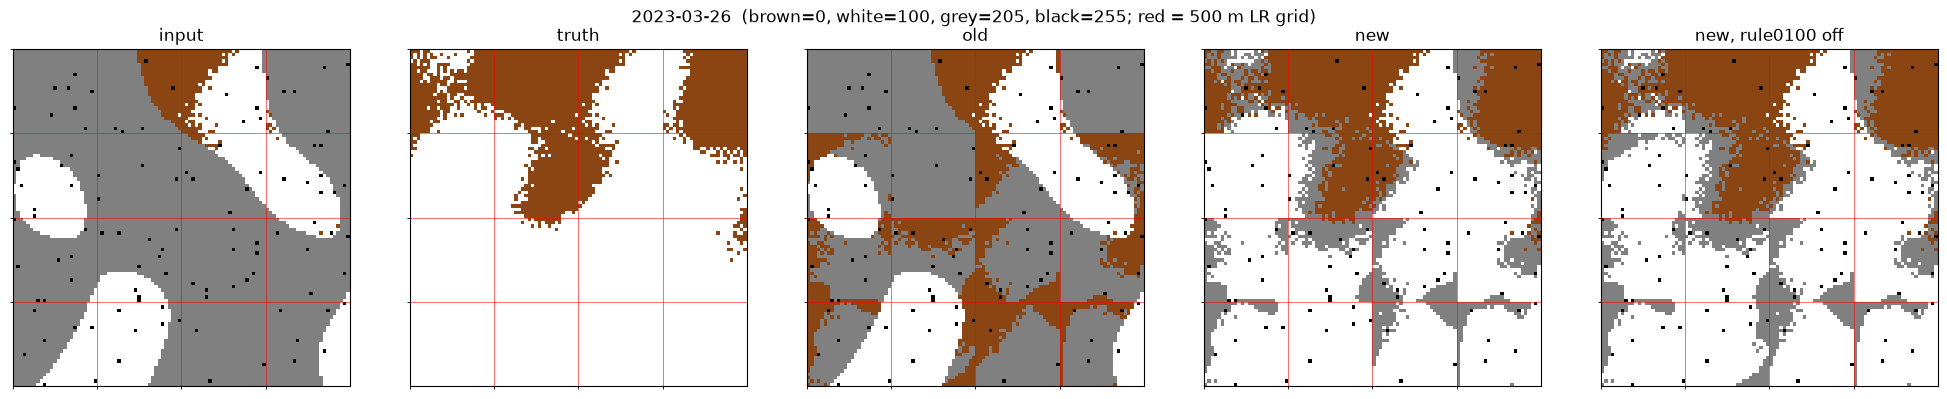

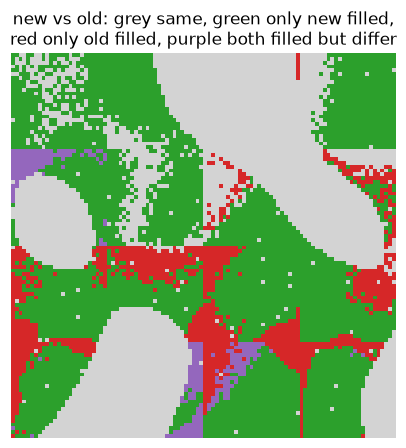

In [10]:
k = int(np.argmax([(inp[i] == 205).mean() for i in range(len(days))]))
cmap = ListedColormap(['saddlebrown', 'white', 'grey', 'black'])
norm = BoundaryNorm([-1, 50, 150, 230, 260], cmap.N)
panels = {'input': inp[k]} | ({'truth': ref[k]} if ref is not None else {}) | {n: r.isel(bands=0).values[k] for n, r in runs.items()}
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 4))
for ax, (title, a) in zip(axes, panels.items()):
    ax.imshow(a, cmap=cmap, norm=norm, interpolation='nearest')
    ax.set_title(title)
    ax.set_xticks(np.arange(0, NX if REAL_INPUT is None else a.shape[1], 25) - 0.5, minor=True)
    ax.set_yticks(np.arange(0, NY if REAL_INPUT is None else a.shape[0], 25) - 0.5, minor=True)
    ax.grid(which='minor', color='red', lw=0.4)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'{pd.Timestamp(days[k]).date()}  (brown=0, white=100, grey=205, black=255; red = 500 m LR grid)')
plt.tight_layout()

old, new = runs['old'].isel(bands=0).values[k].astype(float), runs['new'].isel(bands=0).values[k].astype(float)
diff = np.select([old == new, (old > 100) & (new <= 100), (old <= 100) & (new > 100)], [0, 1, 2], 3)
plt.figure(figsize=(5, 5))
plt.imshow(diff, cmap=ListedColormap(['lightgrey', 'tab:green', 'tab:red', 'tab:purple']), vmin=-0.5, vmax=3.5, interpolation='nearest')
plt.title('new vs old: grey same, green only new filled,\nred only old filled, purple both filled but differ')
plt.axis('off');